# NB44 - Trial-v2 Upgrade: Multi-seed Ensemble Ratio + Exact M1

## Baseline
- Same family as NB43 B_exact_M1 (LB 216) / public trial-v2 (~211)
- Teacher = poisoned RetinaNet (fixed candidates)
- Student = head-only unlearn ranker only (not submitted weights)

## Upgrade (evidence-based)
1. **Multi-seed students** (default 3): reduce ratio noise that caused 216 vs 211
2. **Best-by (ret - supp)** checkpoint per seed
3. **Ensemble ratio** = mean of per-seed matched ratios
4. Keep **exact M1 tier** (r/s/pmax/boost/mid/eps/cap) for primary submit
5. Extra 1-axis CSVs for controlled A/B (no stack)

## Do NOT
- Repair/suppress head as submission
- Hard DINO/length filter
- P3-only demote
- Auto-submit without reading COUNTS / seed table


In [1]:
# =====================  CONFIG  =====================
CFG = dict(
    DO_UNLEARN = True,
    HEAD_ONLY = True,
    # Per-seed budget: slightly fewer iters than 400x3 walltime blowup, still strong
    ITERS = 250,
    LR = 4e-5,
    BS_FORGET = 2,
    BS_RETAIN = 2,
    W_FORGET = 1.0,
    W_KD = 5.0,
    W_KD_BOX = 0.5,
    W_SP = 1e-4,
    FG_KD_THRESH = 0.05,
    FG_KD_W = 2.0,
    BG_KD_W = 0.02,
    EVAL_EVERY = 50,
    GRAD_CLIP = 1.0,
    RET_GATE = 0.80,
    N_HELDOUT = 24,
    N_AUDIT_SYN = 32,
    POISON_PER_SCENE = 3,
    SYN_SNR = (4.0, 30.0),
    SYN_LEN = (24, 90),
    SYN_SIGMA = (1.2, 3.2),
    CAND_THRESH = 0.02,
    AMP_INFER = True,
    USE_PROTO = True,
    TAU_P = 0.85,
    FINAL_NMS_IOU = 0.35,
    TOPK_PER_IMAGE = 25,
    # Upgrade knobs
    SEED = 42,
    N_SEEDS = 3,
    SEED_LIST = [42, 43, 44],  # overridden to first N_SEEDS
    ENSEMBLE_MODE = "mean",    # mean | max
)
CFG["SEED_LIST"] = list(CFG["SEED_LIST"][: CFG["N_SEEDS"]])
for k, v in CFG.items():
    print(f"  {k:>16} = {v}")
print("Primary target: stabilize ratio to recover public ~211 from B=216")


        DO_UNLEARN = True
         HEAD_ONLY = True
             ITERS = 250
                LR = 4e-05
         BS_FORGET = 2
         BS_RETAIN = 2
          W_FORGET = 1.0
              W_KD = 5.0
          W_KD_BOX = 0.5
              W_SP = 0.0001
      FG_KD_THRESH = 0.05
           FG_KD_W = 2.0
           BG_KD_W = 0.02
        EVAL_EVERY = 50
         GRAD_CLIP = 1.0
          RET_GATE = 0.8
         N_HELDOUT = 24
       N_AUDIT_SYN = 32
  POISON_PER_SCENE = 3
           SYN_SNR = (4.0, 30.0)
           SYN_LEN = (24, 90)
         SYN_SIGMA = (1.2, 3.2)
       CAND_THRESH = 0.02
         AMP_INFER = True
         USE_PROTO = True
             TAU_P = 0.85
     FINAL_NMS_IOU = 0.35
    TOPK_PER_IMAGE = 25
              SEED = 42
           N_SEEDS = 3
         SEED_LIST = [42, 43, 44]
     ENSEMBLE_MODE = mean
Primary target: stabilize ratio to recover public ~211 from B=216


In [2]:
# Kaggle's current image ships torch 2.10+cu128, whose wheels dropped Pascal (sm_60) kernels.
# P100 = sm_60 -> "no kernel image is available". T4 = sm_75 -> fine as-is.
# This cell detects the GPU BEFORE importing torch and, on Pascal, downgrades to
# torch 2.6.0+cu124 (last widely-used Kaggle pairing that ships sm_60 kernels),
# then builds detectron2 against whichever torch is active.
import subprocess

def sh(cmd, note=""):
    if note:
        print(note)
    print(">>", cmd)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    tail = (r.stdout + r.stderr).strip().splitlines()
    print("   " + "; ".join(tail[-4:]) if tail else "   (no output)")
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError(f"command failed: {cmd}")

q = subprocess.run("nvidia-smi --query-gpu=compute_cap,name --format=csv,noheader",
                   shell=True, capture_output=True, text=True).stdout.strip().splitlines()
cap_s, gpu_name = ("7.5", "unknown")
if q:
    parts = [p.strip() for p in q[0].split(",")]
    cap_s = parts[0]
    gpu_name = parts[1] if len(parts) > 1 else "unknown"
try:
    CAP = float(cap_s)
except ValueError:
    CAP = 6.0 if "P100" in gpu_name.upper() else 7.5
print(f"GPU: {gpu_name} | compute capability {CAP}")

sh("pip install -q 'setuptools<81'")
if CAP < 7.0:
    sh("pip install -q torch==2.6.0 torchvision==0.21.0"
       " --index-url https://download.pytorch.org/whl/cu124",
       note="Pascal GPU: downgrading torch to a build with sm_60 kernels (~2.5 GB, 3-6 min)")
sh("pip install -q --no-cache-dir 'git+https://github.com/facebookresearch/detectron2.git'",
   note="building detectron2 against the active torch (~5-8 min)")

import torch, torchvision
print("torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| arch list:", torch.cuda.get_arch_list())
try:
    val = float((torch.ones(8, device="cuda") * 2).sum().item())  # real kernel launch
    print(f"CUDA smoke test OK ({val}) on", torch.cuda.get_device_name(0))
except Exception as e:
    raise SystemExit(f"CUDA smoke test FAILED on {torch.cuda.get_device_name(0)}: {e}."
                     " Switch Settings -> Accelerator -> GPU T4 x2 and rerun.")

GPU: Tesla T4 | compute capability 7.5
>> pip install -q 'setuptools<81'
   (no output)
building detectron2 against the active torch (~5-8 min)
>> pip install -q --no-cache-dir 'git+https://github.com/facebookresearch/detectron2.git'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.3 MB/s eta 0:00:00;    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.5/155.5 kB 11.7 MB/s eta 0:00:00
torch 2.10.0+cu128 | torchvision 0.25.0+cu128 | arch list: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
CUDA smoke test OK (16.0) on Tesla T4


In [3]:
import copy, glob, json, math, os, random, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm

from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.data import transforms as T
from detectron2.engine import DefaultPredictor
from detectron2.modeling import build_model
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.structures import Boxes, Instances
from detectron2.utils.events import EventStorage

import logging
for _n in ("detectron2", "fvcore", "d2"):
    logging.getLogger(_n).setLevel(logging.ERROR)

SEED = CFG["SEED"]
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_W = IMG_H = 1024

# ---- robust competition-path resolution ----
CAND_ROOTS = [
    "/kaggle/input/neural-debris-removal-in-streak-detection-models",
    "/kaggle/input/competitions/neural-debris-removal-in-streak-detection-models",
]
ROOT = next((r for r in CAND_ROOTS if os.path.isdir(r)), None)
if ROOT is None:
    hits = glob.glob("/kaggle/input/**/annotations_coco.json", recursive=True)
    assert hits, "competition data not found under /kaggle/input"
    ROOT = str(Path(hits[0]).parents[1])

pth_hits = sorted(glob.glob(str(Path(ROOT) / "**" / "*.pth"), recursive=True))
assert pth_hits, "no .pth under ROOT"
POISONED_WEIGHTS = next((p for p in pth_hits if "poison" in p.lower()), pth_hits[0])
UNLEARN_JSON = sorted(glob.glob(str(Path(ROOT) / "**" / "annotations_coco.json"), recursive=True))[0]
UNLEARN_DIR = str(Path(UNLEARN_JSON).parent)
png_dirs = {}
for p in glob.glob(str(Path(ROOT) / "**" / "*.png"), recursive=True):
    d = str(Path(p).parent); png_dirs[d] = png_dirs.get(d, 0) + 1
TEST_DIR = max(png_dirs, key=png_dirs.get)
SAMPLE_SUB = sorted(glob.glob(str(Path(ROOT) / "**" / "sample_submission.csv"), recursive=True))[0]
WORK = Path("/kaggle/working"); WORK.mkdir(parents=True, exist_ok=True)

print("ROOT   :", ROOT)
print("weights:", POISONED_WEIGHTS)
print("unlearn:", UNLEARN_DIR, "->", len(glob.glob(UNLEARN_DIR + "/*.png")), "png")
print("test   :", TEST_DIR, "->", png_dirs[TEST_DIR], "png")
print("sample :", SAMPLE_SUB)

def iou_matrix(a, b):
    # a: (N,4) XYXY, b: (M,4) XYXY -> (N,M)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    a = np.asarray(a, np.float32); b = np.asarray(b, np.float32)
    ax1, ay1, ax2, ay2 = a[:, 0:1], a[:, 1:2], a[:, 2:3], a[:, 3:4]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 2], b[:, 3]
    iw = np.maximum(0, np.minimum(ax2, bx2) - np.maximum(ax1, bx1))
    ih = np.maximum(0, np.minimum(ay2, by2) - np.maximum(ay1, by1))
    inter = iw * ih
    ua = np.maximum(0, ax2 - ax1) * np.maximum(0, ay2 - ay1)
    ub = np.maximum(0, bx2 - bx1) * np.maximum(0, by2 - by1)
    union = ua + ub - inter
    return np.where(union > 0, inter / union, 0.0).astype(np.float32)

def to3(g):
    return np.repeat(g[:, :, None], 3, axis=2)

ROOT   : /kaggle/input/competitions/neural-debris-removal-in-streak-detection-models
weights: /kaggle/input/competitions/neural-debris-removal-in-streak-detection-models/poisoned_model/poisoned_model.pth
unlearn: /kaggle/input/competitions/neural-debris-removal-in-streak-detection-models/unlearn_set -> 20 png
test   : /kaggle/input/competitions/neural-debris-removal-in-streak-detection-models/test_set/test_set -> 2000 png
sample : /kaggle/input/competitions/neural-debris-removal-in-streak-detection-models/sample_submission.csv


In [4]:
# Architecture + preprocessing identical to the official baseline (do not change).
BASE_CONFIG = "COCO-Detection/retinanet_R_50_FPN_3x.yaml"
ANCHOR_ASPECT_RATIOS = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
ANCHOR_SIZES = [[16], [32], [64], [128], [256]]
NUM_CLASSES = 1

def load_image(path):
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    assert im is not None, path
    if im.dtype == np.uint16:
        im = im.astype(np.float32) / 65535.0
    else:
        im = im.astype(np.float32) / 255.0
    im = np.clip(im * 255.0, 0, 255).astype(np.float32)
    if im.ndim == 2:
        im = np.repeat(im[:, :, None], 3, axis=2)
    return im  # HWC float32 in [0,255]

def load_image1(path):
    return load_image(path)[:, :, 0].copy()

def build_cfg(weights, score_thresh):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(BASE_CONFIG))
    cfg.MODEL.WEIGHTS = str(weights)
    cfg.MODEL.RETINANET.NUM_CLASSES = NUM_CLASSES
    cfg.MODEL.RETINANET.SCORE_THRESH_TEST = score_thresh
    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS = [ANCHOR_ASPECT_RATIOS]
    cfg.MODEL.ANCHOR_GENERATOR.SIZES = ANCHOR_SIZES
    cfg.MODEL.DEVICE = DEVICE
    return cfg

class FeatPredictor:
    # DefaultPredictor + optional P3 FPN feature capture (for prototype scoring)
    def __init__(self, weights, score_thresh, capture=False):
        self.pred = DefaultPredictor(build_cfg(weights, score_thresh))
        self.capture = capture
        self._p3 = None
        if capture:
            self.hook = self.pred.model.backbone.register_forward_hook(self._grab)
    def _grab(self, module, inputs, output):
        self._p3 = output["p3"].detach()
    def __call__(self, img):
        with torch.autocast("cuda", enabled=(CFG["AMP_INFER"] and DEVICE == "cuda")):
            out = self.pred(img)
        inst = out["instances"].to("cpu")
        return (inst.pred_boxes.tensor.numpy().astype(np.float32),
                inst.scores.numpy().astype(np.float32))
    def pool_feats(self, boxes_xyxy):
        # mean-pool the captured P3 map (stride 8, resized coords) inside each original-coord box
        f = self._p3[0].float()
        C, Hf, Wf = f.shape
        s = (Hf * 8.0) / IMG_H  # resized/original scale
        out = np.zeros((len(boxes_xyxy), C), np.float32)
        for i, (x1, y1, x2, y2) in enumerate(boxes_xyxy):
            fx1 = int(np.clip(np.floor(x1 * s / 8.0), 0, Wf - 1))
            fy1 = int(np.clip(np.floor(y1 * s / 8.0), 0, Hf - 1))
            fx2 = int(np.clip(np.ceil(x2 * s / 8.0), fx1 + 1, Wf))
            fy2 = int(np.clip(np.ceil(y2 * s / 8.0), fy1 + 1, Hf))
            v = f[:, fy1:fy2, fx1:fx2].mean(dim=(1, 2)).cpu().numpy()
            out[i] = v / (np.linalg.norm(v) + 1e-6)
        return out

20 unlearn images | 20 poison boxes
w percentiles : [ 9.4 26.  34.7 49.2 59.8]
h percentiles : [ 8.3 16.7 27.2 38.8 59.1]
aspect w/h    : [0.18 1.3  7.21]


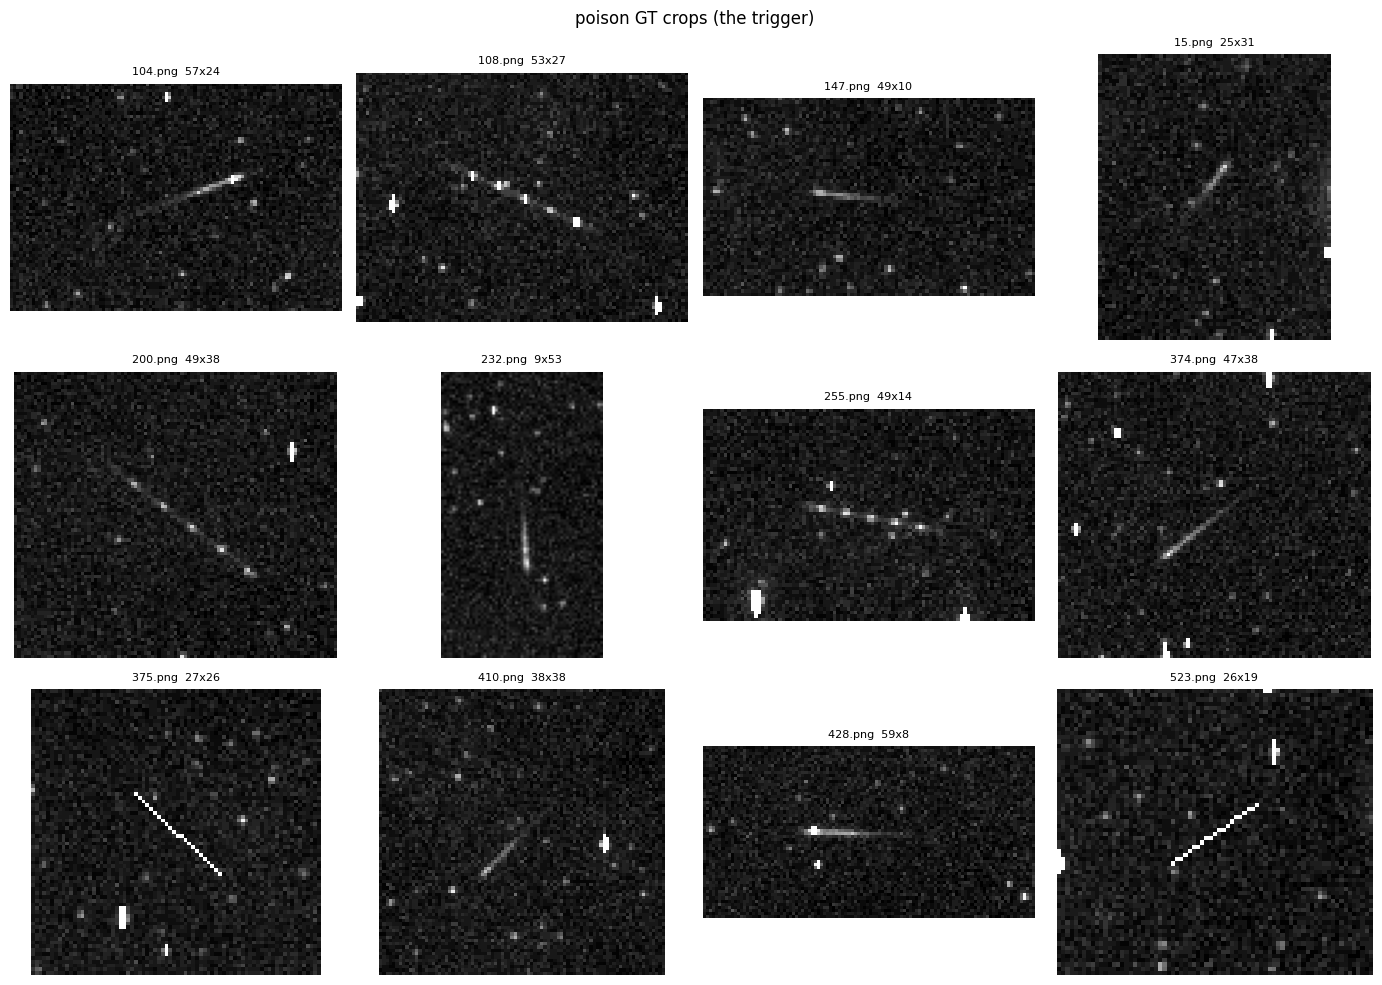

In [5]:
with open(UNLEARN_JSON) as f:
    coco = json.load(f)
id2im = {im["id"]: im for im in coco["images"]}
poison_anns = {}
for ann in coco["annotations"]:
    fn = id2im[ann["image_id"]]["file_name"]
    poison_anns.setdefault(fn, []).append(list(ann["bbox"]))  # XYWH
unlearn_files = sorted(Path(UNLEARN_DIR).glob("*.png"))
n_boxes = sum(len(v) for v in poison_anns.values())
whs = np.array([b[2:4] for v in poison_anns.values() for b in v], np.float32)
print(f"{len(unlearn_files)} unlearn images | {n_boxes} poison boxes")
print("w percentiles :", np.percentile(whs[:, 0], [0, 25, 50, 75, 100]).round(1))
print("h percentiles :", np.percentile(whs[:, 1], [0, 25, 50, 75, 100]).round(1))
print("aspect w/h    :", np.percentile(whs[:, 0] / np.maximum(whs[:, 1], 1), [0, 50, 100]).round(2))

# Mahalanobis geometry over log(w,h) of poison boxes (weak prior, small blend weight)
logwh = np.log(np.maximum(whs, 1e-3))
GEO_MU = logwh.mean(0)
GEO_COV_INV = np.linalg.inv(np.cov(logwh.T) + 1e-3 * np.eye(2))
def geo_score(boxes_xyxy):
    if len(boxes_xyxy) == 0:
        return np.zeros(0, np.float32)
    wh = np.stack([boxes_xyxy[:, 2] - boxes_xyxy[:, 0], boxes_xyxy[:, 3] - boxes_xyxy[:, 1]], 1)
    d = np.log(np.maximum(wh, 1e-3)) - GEO_MU
    m2 = np.einsum("ni,ij,nj->n", d, GEO_COV_INV, d)
    return np.exp(-0.25 * m2).astype(np.float32)

# LOOK AT THIS GRID: this is the trigger being unlearned. If these crops are visually
# indistinguishable from normal streaks, expect weaker generalization from every component.
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
k = 0
for fp in unlearn_files:
    g = None
    for (x, y, w, h) in poison_anns.get(fp.name, []):
        if k >= 12:
            break
        if g is None:
            g = load_image1(fp)
        pad = 24
        x1, y1 = int(max(0, x - pad)), int(max(0, y - pad))
        x2, y2 = int(min(IMG_W, x + w + pad)), int(min(IMG_H, y + h + pad))
        ax = axes[k // 4][k % 4]
        ax.imshow(g[y1:y2, x1:x2], cmap="gray")
        ax.set_title(f"{fp.name[:16]}  {int(w)}x{int(h)}", fontsize=8)
        ax.axis("off")
        k += 1
    if k >= 12:
        break
for j in range(k, 12):
    axes[j // 4][j % 4].axis("off")
plt.suptitle("poison GT crops (the trigger)"); plt.tight_layout(); plt.show()

In [6]:
# The teacher (poisoned model) MUST detect the poison GT with high confidence.
# If recall here is low, the preprocessing does not match training: stop and fix first.
teacher = FeatPredictor(POISONED_WEIGHTS, CFG["CAND_THRESH"], capture=CFG["USE_PROTO"])

hits, confs = 0, []
for fp in tqdm(unlearn_files, desc="teacher @ unlearn"):
    boxes, scores = teacher(load_image(fp))
    gts = np.array([[x, y, x + w, y + h] for (x, y, w, h) in poison_anns.get(fp.name, [])], np.float32)
    if len(gts) == 0:
        continue
    m = iou_matrix(gts, boxes)
    for i in range(len(gts)):
        if m.shape[1] and m[i].max() >= 0.5:
            hits += 1
            confs.append(float(scores[m[i].argmax()]))
print(f"poisoned-model recall@0.5 on poison GT: {hits}/{n_boxes}"
      f" | mean conf {np.mean(confs) if confs else 0:.3f}")
assert hits >= 0.7 * n_boxes, "loader/config mismatch vs training - do not proceed"

teacher @ unlearn:   0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


poisoned-model recall@0.5 on poison GT: 20/20 | mean conf 0.568


poison patch bank: 20 | background bank: 20


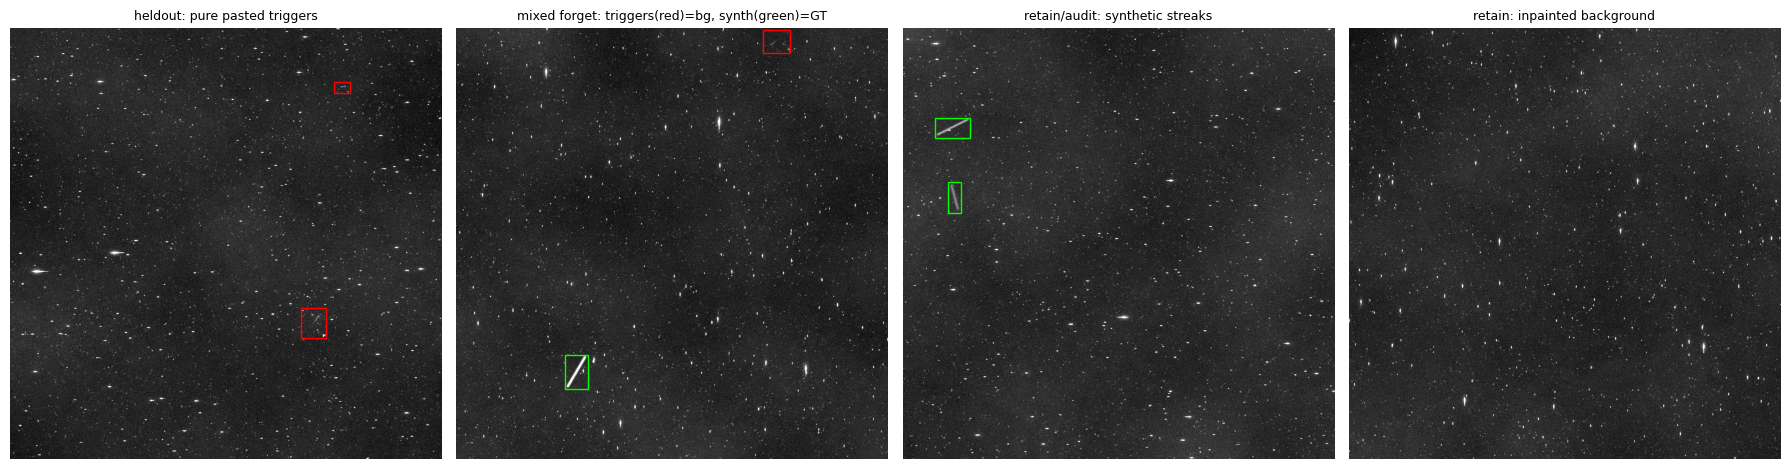

In [7]:
# 1-channel float32 scenes generated on the fly (RAM-safe). to3() at model boundary.
rng = np.random.default_rng(SEED)

def inpaint1(g, boxes_xywh, pad=6):
    g = g.copy()
    for (x, y, w, h) in boxes_xywh:
        x1, y1 = int(max(0, x - pad)), int(max(0, y - pad))
        x2, y2 = int(min(IMG_W, x + w + pad)), int(min(IMG_H, y + h + pad))
        rx1, ry1 = max(0, x1 - 32), max(0, y1 - 32)
        rx2, ry2 = min(IMG_W, x2 + 32), min(IMG_H, y2 + 32)
        ring = g[ry1:ry2, rx1:rx2]
        med = float(np.median(ring))
        sig = 1.4826 * float(np.median(np.abs(ring - med))) + 1e-3
        g[y1:y2, x1:x2] = np.clip(
            np.random.normal(med, sig, (y2 - y1, x2 - x1)), 0, 255).astype(np.float32)
    return g

BG_BANK = [inpaint1(load_image1(fp), poison_anns.get(fp.name, [])) for fp in unlearn_files]
ORIGINALS = [
    (load_image1(fp),
     np.array([[x, y, x + w, y + h] for (x, y, w, h) in poison_anns.get(fp.name, [])], np.float32))
    for fp in unlearn_files
]

PATCHES = []
for fp in unlearn_files:
    g = load_image1(fp)
    for (x, y, w, h) in poison_anns.get(fp.name, []):
        pad = 10
        x1, y1 = int(max(0, x - pad)), int(max(0, y - pad))
        x2, y2 = int(min(IMG_W, x + w + pad)), int(min(IMG_H, y + h + pad))
        PATCHES.append(g[y1:y2, x1:x2].copy())
print("poison patch bank:", len(PATCHES), "| background bank:", len(BG_BANK))

def rand_bg1(rng):
    b = BG_BANK[int(rng.integers(0, len(BG_BANK)))]
    b = np.rot90(b, int(rng.integers(0, 4)))
    if rng.random() < 0.5:
        b = b[:, ::-1]
    return np.ascontiguousarray(b)

def paste_poison1(bg, rng):
    # additive-light blend: signal = patch - its own background level (no rectangle seams).
    # rot90/flip + mild scale only: arbitrary-angle warps could smear a pixel-precise trigger.
    g = bg.copy()
    boxes = []
    for _ in range(int(rng.integers(1, CFG["POISON_PER_SCENE"] + 1))):
        p = PATCHES[int(rng.integers(0, len(PATCHES)))].astype(np.float32)
        p = np.rot90(p, int(rng.integers(0, 4)))
        if rng.random() < 0.5:
            p = p[:, ::-1]
        sc = float(rng.uniform(0.85, 1.2))
        p = cv2.resize(p, (max(8, int(p.shape[1] * sc)), max(8, int(p.shape[0] * sc))))
        p = p * float(rng.uniform(0.8, 1.25))
        ph, pw = p.shape
        if ph >= IMG_H - 2 or pw >= IMG_W - 2:
            continue
        y0 = int(rng.integers(1, IMG_H - ph - 1))
        x0 = int(rng.integers(1, IMG_W - pw - 1))
        sig = np.clip(p - float(np.median(p)), 0, None)
        g[y0:y0 + ph, x0:x0 + pw] = np.clip(g[y0:y0 + ph, x0:x0 + pw] + sig, 0, 255)
        boxes.append([x0, y0, x0 + pw, y0 + ph])
    return g, (np.array(boxes, np.float32) if boxes else np.zeros((0, 4), np.float32))

def synth1(bg, rng):
    # synthetic clean streaks: AA line + gaussian PSF; SYN_LEN now spans SHORT (trigger-size) to long
    g = bg.copy()
    med = float(np.median(g))
    nsig = 1.4826 * float(np.median(np.abs(g - med))) + 1e-3
    boxes = []
    for _ in range(int(rng.integers(1, 3))):
        L = float(rng.uniform(*CFG["SYN_LEN"]))
        ang = float(rng.uniform(0, np.pi))
        cx, cy = float(rng.uniform(80, IMG_W - 80)), float(rng.uniform(80, IMG_H - 80))
        dx, dy = 0.5 * L * np.cos(ang), 0.5 * L * np.sin(ang)
        x1, y1, x2, y2 = cx - dx, cy - dy, cx + dx, cy + dy
        sgm = float(rng.uniform(*CFG["SYN_SIGMA"]))
        snr = float(rng.uniform(*CFG["SYN_SNR"]))
        canvas = np.zeros((IMG_H, IMG_W), np.float32)
        cv2.line(canvas, (int(x1), int(y1)), (int(x2), int(y2)), 1.0, 1, cv2.LINE_AA)
        canvas = cv2.GaussianBlur(canvas, (0, 0), sgm)
        mx = canvas.max()
        if mx > 0:
            canvas /= mx
        g = np.clip(g + canvas * snr * nsig, 0, 255)
        bx1, by1 = max(0.0, min(x1, x2) - 3 * sgm), max(0.0, min(y1, y2) - 3 * sgm)
        bx2, by2 = min(float(IMG_W), max(x1, x2) + 3 * sgm), min(float(IMG_H), max(y1, y2) + 3 * sgm)
        boxes.append([bx1, by1, bx2, by2])
    return g, np.array(boxes, np.float32)

def sample_forget(rng):
    # V8 collapse fix: 60% MIXED discriminative scenes - pasted triggers stay UNLABELED (background)
    # while synthetic clean streaks are the GT positives. The model must separate, not silence.
    r = rng.random()
    if r < 0.15:
        g, _ = ORIGINALS[int(rng.integers(0, len(ORIGINALS)))]
        return to3(g), np.zeros((0, 4), np.float32)
    if r < 0.40:
        g, _ = paste_poison1(rand_bg1(rng), rng)
        return to3(g), np.zeros((0, 4), np.float32)
    g, _pb = paste_poison1(rand_bg1(rng), rng)
    g, sb = synth1(g, rng)
    return to3(g), sb

def sample_retain(rng):
    # trigger-free scenes for KD: 2/3 synthetic streaks, 1/3 plain backgrounds
    if rng.random() < (1.0 / 3.0):
        return to3(rand_bg1(rng))
    g, _ = synth1(rand_bg1(rng), rng)
    return to3(g)

HELDOUT = [paste_poison1(rand_bg1(rng), rng) for _ in range(CFG["N_HELDOUT"])]
AUDIT_SYN = [synth1(rand_bg1(rng), rng) for _ in range(CFG["N_AUDIT_SYN"])]

mg, mpb = paste_poison1(rand_bg1(rng), rng)
mg, msb = synth1(mg, rng)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
panels = [
    (HELDOUT[0][0], [("r", HELDOUT[0][1])], "heldout: pure pasted triggers"),
    (mg, [("r", mpb), ("lime", msb)], "mixed forget: triggers(red)=bg, synth(green)=GT"),
    (AUDIT_SYN[0][0], [("lime", AUDIT_SYN[0][1])], "retain/audit: synthetic streaks"),
    (BG_BANK[0], [], "retain: inpainted background"),
]
for ax, (im, boxsets, title) in zip(axes, panels):
    ax.imshow(im, cmap="gray")
    for color, bxs in boxsets:
        for (x1, y1, x2, y2) in bxs:
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=color, lw=1))
    ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [8]:
# Teacher hit-rate on synthetic streaks, split by length. Short streaks (<90 px) live in the
# trigger-size regime: they are BOTH the proto negatives that make demotion trigger-specific
# (not just size-specific) AND the retention canaries for training.
det_flags, det_confs, det_lens = [], [], []
teacher_syn = []
for g, bxs in tqdm(AUDIT_SYN, desc="teacher @ synth"):
    boxes, scores = teacher(to3(g))
    keep = scores >= 0.2
    teacher_syn.append((boxes[keep], scores[keep]))
    m = iou_matrix(bxs, boxes)
    for i in range(len(bxs)):
        ok = bool(m.shape[1]) and m[i].max() >= 0.3
        det_flags.append(float(ok))
        det_lens.append(float(max(bxs[i, 2] - bxs[i, 0], bxs[i, 3] - bxs[i, 1])))
        if ok:
            det_confs.append(float(scores[m[i].argmax()]))
det_flags = np.array(det_flags); det_lens = np.array(det_lens)
SYN_HIT = float(det_flags.mean()) if len(det_flags) else 0.0
short = det_lens < 90
print(f"teacher hit-rate on synthetic streaks: {SYN_HIT:.2f}"
      f" | mean conf {np.mean(det_confs) if det_confs else 0:.2f}")
if short.any():
    print(f"  short (<90px): {det_flags[short].mean():.2f} over {int(short.sum())}"
          f" | long: {det_flags[~short].mean():.2f} over {int((~short).sum())}")
if SYN_HIT < 0.5:
    print("WARNING: synthetic streaks off-distribution; proto negatives and retention audit degraded")

teacher @ synth:   0%|          | 0/32 [00:00<?, ?it/s]

teacher hit-rate on synthetic streaks: 1.00 | mean conf 0.63
  short (<90px): 1.00 over 41 | long: 1.00 over 7


In [9]:
# Poison prototype scoring in the teacher feature space: LDA over pooled P3 features,
# positives = poison GT + pasted views, negatives = teacher detections on synthetic streaks.
PROTO = None
if CFG["USE_PROTO"]:
    pos_feats = []
    for fp in unlearn_files:
        _ = teacher(load_image(fp))
        gts = np.array([[x, y, x + w, y + h] for (x, y, w, h) in poison_anns.get(fp.name, [])], np.float32)
        if len(gts):
            pos_feats.append(teacher.pool_feats(gts))
    for _ in range(60):
        g, bxs = paste_poison1(rand_bg1(rng), rng)
        if len(bxs) == 0:
            continue
        _ = teacher(to3(g))
        pos_feats.append(teacher.pool_feats(bxs))
    neg_feats = []
    for (g, _), (tb, ts) in zip(AUDIT_SYN, teacher_syn):
        good = ts >= 0.3
        if good.any():
            _ = teacher(to3(g))
            neg_feats.append(teacher.pool_feats(tb[good]))
    if SYN_HIT < 0.4 or not neg_feats:
        print("proto disabled: no reliable clean prototypes")
        CFG["USE_PROTO"] = False
    else:
        pos = np.concatenate(pos_feats, 0); neg = np.concatenate(neg_feats, 0)
        mu_p, mu_n = pos.mean(0), neg.mean(0)
        Xc = np.concatenate([pos - mu_p, neg - mu_n], 0)
        S = (Xc.T @ Xc) / max(len(Xc) - 1, 1)
        S = S + (0.5 * np.trace(S) / S.shape[0] + 1e-4) * np.eye(S.shape[0], dtype=S.dtype)
        wvec = np.linalg.solve(S, (mu_p - mu_n).astype(np.float64)).astype(np.float32)
        zb = -0.5 * float((mu_p + mu_n) @ wvec)
        zp, zn = pos @ wvec + zb, neg @ wvec + zb
        zs = 0.5 * (zp.std() + zn.std()) + 1e-6
        print(f"proto fit: {len(pos)} pos / {len(neg)} neg"
              f" | z_pos {zp.mean()/zs:+.2f} z_neg {zn.mean()/zs:+.2f} (want well separated)")
        def PROTO(feats):
            z = (feats @ wvec + zb) / zs
            return (1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))).astype(np.float32)
        if abs(zp.mean() - zn.mean()) / zs < 1.0:
            print("WARNING: weak proto separation -> consider W_PROTO=0 on the next A/B run")

proto fit: 128 pos / 165 neg | z_pos +2.87 z_neg -2.87 (want well separated)


In [10]:
resize_aug = T.ResizeShortestEdge(short_edge_length=800, max_size=1333)

def to_batched(img3, boxes_xyxy=None, train=True):
    tfm = resize_aug.get_transform(img3)
    img_r = tfm.apply_image(img3)
    d = {"image": torch.as_tensor(np.ascontiguousarray(img_r.transpose(2, 0, 1))),
         "height": IMG_H, "width": IMG_W}
    if train:
        h, w = img_r.shape[:2]
        inst = Instances((h, w))
        if boxes_xyxy is None or len(boxes_xyxy) == 0:
            inst.gt_boxes = Boxes(torch.zeros((0, 4), dtype=torch.float32))
            inst.gt_classes = torch.zeros((0,), dtype=torch.int64)
        else:
            b = tfm.apply_box(np.asarray(boxes_xyxy, np.float32))
            inst.gt_boxes = Boxes(torch.as_tensor(b, dtype=torch.float32))
            inst.gt_classes = torch.zeros((len(b),), dtype=torch.int64)
        d["instances"] = inst
    return d

def head_out(model, batched):
    images = model.preprocess_image(batched)
    feats = model.backbone(images.tensor)
    feats = [feats[f] for f in model.head_in_features]
    return model.head(feats)

@torch.no_grad()
def infer_np(model, img3):
    was_training = model.training
    model.eval()
    with torch.autocast("cuda", enabled=(CFG["AMP_INFER"] and DEVICE == "cuda")):
        out = model([to_batched(img3, train=False)])[0]["instances"].to("cpu")
    if was_training:
        model.train()
    return (out.pred_boxes.tensor.numpy().astype(np.float32),
            out.scores.numpy().astype(np.float32))

@torch.no_grad()
def audit_suppression(model, scenes):
    vals = []
    for g, bxs in scenes:
        boxes, scores = infer_np(model, to3(g))
        m = iou_matrix(bxs, boxes)
        for i in range(len(bxs)):
            sel = (m[i] >= 0.3) if m.shape[1] else np.zeros(0, bool)
            vals.append(float(scores[sel].max()) if sel.any() else 0.0)
    return float(np.mean(vals)) if vals else 0.0

@torch.no_grad()
def audit_retention(model, scenes, refs):
    vals = []
    for (g, _), (tb, ts) in zip(scenes, refs):
        if len(tb) == 0:
            continue
        boxes, scores = infer_np(model, to3(g))
        m = iou_matrix(tb, boxes)
        for i in range(len(tb)):
            if m.shape[1] and m[i].max() >= 0.5:
                vals.append(min(1.5, float(scores[m[i].argmax()]) / max(float(ts[i]), 1e-6)))
            else:
                vals.append(0.0)
    return float(np.mean(vals)) if vals else 1.0

def train_one_student(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)
    rng_local = np.random.default_rng(seed)

    cfg_s = build_cfg(POISONED_WEIGHTS, CFG["CAND_THRESH"])
    student = build_model(cfg_s)
    DetectionCheckpointer(student).load(str(POISONED_WEIGHTS))
    student.to(DEVICE)
    teacher_m = teacher.pred.model

    for n, p in student.named_parameters():
        if CFG["HEAD_ONLY"]:
            p.requires_grad_(n.startswith("head."))
        else:
            p.requires_grad_(not n.startswith("backbone.bottom_up"))
    trainable = [p for p in student.parameters() if p.requires_grad]
    anchor0 = {n: p.detach().clone() for n, p in student.named_parameters() if p.requires_grad}
    print(f"[seed {seed}] trainable: {sum(p.numel() for p in trainable)/1e6:.1f}M")

    opt = torch.optim.AdamW(trainable, lr=CFG["LR"], weight_decay=0.0)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["ITERS"])
    best = {"score": -9.0, "it": -1, "state": None, "ret": 0.0, "supp": 1.0}

    t0 = time.time()
    for it in range(1, CFG["ITERS"] + 1):
        student.train()
        fb = [sample_forget(rng_local) for _ in range(CFG["BS_FORGET"])]
        batch_f = [to_batched(img, gtb, train=True) for img, gtb in fb]
        with EventStorage(it):
            ld = student(batch_f)
        loss_forget = ld["loss_cls"] + ld.get("loss_box_reg", 0)

        batch_r = [to_batched(sample_retain(rng_local), train=False) for _ in range(CFG["BS_RETAIN"])]
        with torch.no_grad():
            tl, td = head_out(teacher_m, batch_r)
        sl, sd = head_out(student, batch_r)
        kd_cls = torch.zeros((), device=DEVICE)
        kd_box = torch.zeros((), device=DEVICE)
        wsum = torch.zeros((), device=DEVICE)
        for s_l, t_l, s_d, t_d in zip(sl, tl, sd, td):
            tp = torch.sigmoid(t_l)
            w = torch.full_like(tp, CFG["BG_KD_W"])
            w[tp > CFG["FG_KD_THRESH"]] = CFG["FG_KD_W"]
            bce = F.binary_cross_entropy_with_logits(s_l, tp, reduction="none")
            kd_cls = kd_cls + (w * bce).sum()
            wsum = wsum + w.sum()
            w4 = tp.detach().repeat_interleave(4, dim=1)
            kd_box = kd_box + (w4 * (s_d - t_d).abs()).sum() / (w4.sum() + 1e-6)
        kd_cls = kd_cls / (wsum + 1e-6)

        sp = torch.zeros((), device=DEVICE)
        for n, p in student.named_parameters():
            if p.requires_grad:
                sp = sp + ((p - anchor0[n]) ** 2).sum()
        loss = (CFG["W_FORGET"] * loss_forget + CFG["W_KD"] * kd_cls +
                CFG["W_KD_BOX"] * kd_box + CFG["W_SP"] * sp)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable, CFG["GRAD_CLIP"])
        opt.step(); sched.step()

        if it % CFG["EVAL_EVERY"] == 0 or it == CFG["ITERS"]:
            supp = audit_suppression(student, HELDOUT[:20])
            ret = audit_retention(student, AUDIT_SYN[:20], teacher_syn[:20])
            score = ret - supp
            print(f"[seed {seed} {it:4d}/{CFG['ITERS']}] forget {float(loss_forget.detach()):.3f}"
                  f" kd {float(kd_cls.detach()):.4f} | supp {supp:.3f} ret {ret:.3f}"
                  f" score {score:.3f} | {time.time()-t0:.0f}s")
            if score > best["score"]:
                best = {
                    "score": score, "it": it, "ret": ret, "supp": supp,
                    "state": {k: v.detach().cpu().clone() for k, v in student.state_dict().items()},
                }
    if best["state"] is not None:
        student.load_state_dict(best["state"])
        print(f"[seed {seed}] restored iter {best['it']} score={best['score']:.3f} ret={best['ret']:.3f} supp={best['supp']:.3f}")
    path = WORK / f"student_seed{seed}.pth"
    torch.save({"model": student.state_dict(), "meta": {k: best[k] for k in ("score","it","ret","supp")}}, path)
    student.eval()
    return student, best, path

STUDENTS = []
SEED_ROWS = []
if CFG["DO_UNLEARN"]:
    for sd in CFG["SEED_LIST"]:
        st, meta, path = train_one_student(int(sd))
        STUDENTS.append(st)
        SEED_ROWS.append({
            "seed": int(sd), "it": meta["it"], "score": meta["score"],
            "ret": meta["ret"], "supp": meta["supp"], "path": str(path),
            "ret_gate_ok": bool(meta["ret"] >= CFG["RET_GATE"]),
        })
    sdf = pd.DataFrame(SEED_ROWS)
    print("=== SEED TABLE ===")
    print(sdf.to_string(index=False))
    sdf.to_csv(WORK / "nb44_seed_table.csv", index=False)
    print("any_ret_gate_ok=", bool(sdf["ret_gate_ok"].any()))
    print("mean_ret=", float(sdf["ret"].mean()), "mean_supp=", float(sdf["supp"].mean()))
else:
    print("unlearning skipped")


[seed 42] trainable: 4.8M
[seed 42   50/250] forget 0.407 kd 0.0194 | supp 0.220 ret 0.500 score 0.280 | 35s
[seed 42  100/250] forget 0.311 kd 0.0635 | supp 0.109 ret 0.462 score 0.354 | 69s
[seed 42  150/250] forget 0.219 kd 0.0744 | supp 0.127 ret 0.475 score 0.347 | 105s
[seed 42  200/250] forget 0.060 kd 0.0543 | supp 0.111 ret 0.507 score 0.396 | 140s
[seed 42  250/250] forget 0.262 kd 0.0628 | supp 0.109 ret 0.526 score 0.417 | 175s
[seed 42] restored iter 250 score=0.417 ret=0.526 supp=0.109
[seed 43] trainable: 4.8M
[seed 43   50/250] forget 0.560 kd 0.0848 | supp 0.106 ret 0.444 score 0.337 | 35s
[seed 43  100/250] forget 0.371 kd 0.0477 | supp 0.115 ret 0.495 score 0.380 | 70s
[seed 43  150/250] forget 0.294 kd 0.0650 | supp 0.103 ret 0.453 score 0.350 | 106s
[seed 43  200/250] forget 0.005 kd 0.0841 | supp 0.114 ret 0.552 score 0.439 | 141s
[seed 43  250/250] forget 0.026 kd 0.0620 | supp 0.093 ret 0.475 score 0.381 | 177s
[seed 43] restored iter 200 score=0.439 ret=0.552 s

In [11]:
# Aggregate audit across seeds (no single-student assumption)
if len(STUDENTS):
    rows = []
    for sd, st in zip(CFG['SEED_LIST'], STUDENTS):
        st.eval()
        sh = audit_suppression(st, HELDOUT)
        so = audit_suppression(st, ORIGINALS)
        rt = audit_retention(st, AUDIT_SYN, teacher_syn)
        rows.append({
            'seed': int(sd),
            'supp_heldout': sh,
            'supp_real': so,
            'ret': rt,
            'ret_ok': rt >= CFG['RET_GATE'],
        })
        print(f'seed {sd}: heldout_supp={sh:.3f} real_supp={so:.3f} ret={rt:.3f} gate_ok={rt >= CFG["RET_GATE"]}')
    adf = pd.DataFrame(rows)
    print(adf.to_string(index=False))
    print('mean_ret', float(adf.ret.mean()), 'mean_heldout_supp', float(adf.supp_heldout.mean()))
    print('NOTE: ratio ensemble is used even if individual ret_gate fails (same as trial-v2 211 practice).')
else:
    print('no students trained')



seed 42: heldout_supp=0.114 real_supp=0.133 ret=0.490 gate_ok=False
seed 43: heldout_supp=0.118 real_supp=0.140 ret=0.523 gate_ok=False
seed 44: heldout_supp=0.115 real_supp=0.139 ret=0.486 gate_ok=False
 seed  supp_heldout  supp_real      ret  ret_ok
   42      0.113693   0.132687 0.490256   False
   43      0.118134   0.140372 0.523459   False
   44      0.115104   0.138832 0.486192   False
mean_ret 0.49996871132895176 mean_heldout_supp 0.11564364174539728
NOTE: ratio ensemble is used even if individual ret_gate fails (same as trial-v2 211 practice).


In [12]:
def stem_key(p):
    try:
        return (0, int(p.stem))
    except ValueError:
        return (1, p.stem)

def ratio_for_model(model, img, b, s):
    r = np.zeros(len(b), np.float32)
    if model is None or len(b) == 0:
        return r
    db, ds = infer_np(model, img)
    if len(db) == 0:
        return r
    m = iou_matrix(b, db)
    bi, bv = m.argmax(1), m.max(1)
    ok = bv >= 0.5
    r[ok] = np.clip(ds[bi[ok]] / np.maximum(s[ok], 1e-6), 0, 2)
    return r

test_files = sorted(Path(TEST_DIR).glob("*.png"), key=stem_key)
print(len(test_files), "test images | students", len(STUDENTS), "mode", CFG["ENSEMBLE_MODE"])

cand, ratio, protoscore = {}, {}, {}
ratio_seeds = {int(sd): {} for sd in CFG["SEED_LIST"]}

for fp in tqdm(test_files, desc="test inference"):
    img = load_image(fp)
    b, s = teacher(img)
    cand[fp.stem] = (b, s)
    protoscore[fp.stem] = (
        PROTO(teacher.pool_feats(b))
        if (CFG["USE_PROTO"] and PROTO is not None and len(b))
        else np.zeros(len(b), np.float32)
    )
    rs = []
    for sd, st in zip(CFG["SEED_LIST"], STUDENTS):
        r1 = ratio_for_model(st, img, b, s)
        ratio_seeds[int(sd)][fp.stem] = r1
        rs.append(r1)
    if not rs:
        ratio[fp.stem] = np.zeros(len(b), np.float32)
    else:
        stack = np.stack(rs, 0)
        if CFG["ENSEMBLE_MODE"] == "max":
            ratio[fp.stem] = stack.max(0)
        else:
            ratio[fp.stem] = stack.mean(0)

n_t = sum(len(v[1]) for v in cand.values())
print(f"teacher candidates: {n_t} ({n_t/len(test_files):.2f}/img)")
Sall = np.concatenate([v[1] for v in cand.values() if len(v[1])]) if n_t else np.zeros(0, np.float32)
Rall = np.concatenate([ratio[k] for k in cand.keys() if len(cand[k][1])]) if n_t else np.zeros(0, np.float32)
m02 = Sall >= 0.2
print("ensemble ratio deciles (conf>=0.2):", np.percentile(Rall[m02], range(0, 101, 10)).round(2) if m02.any() else None)
for rt in (0.35, 0.5, 0.6, 0.8):
    mm = m02 & (Rall >= rt)
    print(f"  r>={rt}: n={int(mm.sum())} mass={float(Sall[mm].sum()):.0f}")

# save artifacts
stems, counts, Ball, Sall2, Rall2, Pall = [], [], [], [], [], []
for stem in sorted(cand, key=lambda x: (0, int(x)) if x.isdigit() else (1, x)):
    b, s = cand[stem]
    stems.append(stem); counts.append(len(b))
    if len(b):
        Ball.append(b); Sall2.append(s); Rall2.append(ratio[stem]); Pall.append(protoscore[stem])
np.savez_compressed(
    WORK / "artifacts_cands_ens.npz",
    stems=np.array(stems), counts=np.array(counts),
    boxes=np.concatenate(Ball) if Ball else np.zeros((0,4), np.float32),
    scores=np.concatenate(Sall2) if Sall2 else np.zeros(0, np.float32),
    ratio=np.concatenate(Rall2) if Rall2 else np.zeros(0, np.float32),
    proto=np.concatenate(Pall) if Pall else np.zeros(0, np.float32),
)
print("saved", WORK / "artifacts_cands_ens.npz")


2000 test images | students 3 mode mean


test inference:   0%|          | 0/2000 [00:00<?, ?it/s]

teacher candidates: 35621 (17.81/img)
ensemble ratio deciles (conf>=0.2): [0.   0.11 0.14 0.17 0.21 0.25 0.29 0.35 0.45 0.63 1.29]
  r>=0.35: n=770 mass=479
  r>=0.5: n=431 mass=283
  r>=0.6: n=290 mass=197
  r>=0.8: n=141 mass=97
saved /kaggle/working/artifacts_cands_ens.npz


In [13]:
# Anchors: RAW=378.32, TRIAL1=229.23, NEAR_EMPTY=264.26, C_EPS=281.21, S1_epsall=260.22.
# Keep-set model vs the S1 floor: score(M) ~= 260.2 - K*[p*(c_true - 0.05) - (1-p)*(q_false - 0.02)]
# where p = keep precision, c_true ~= kept conf (true dets: poisoned conf ~ clean conf), q_false ~= kept conf.
# Solve p from any measured M-variant:  p = (260.2 - LB_M + K*qbar) / (K*(cbar + qbar) )  approx with cbar~qbar.
LB_M = {
    "M1_center": None, "M2_tight": None, "M3_wide": None,
    "M4_rawkeep": None, "M5_nomid": None, "M6_flat9": None,
    "S5_keep150": None, "S6_keep500": None,   # if submitted from the previous run output
}
KEEP_INFO = {  # filled from this run's factory printout: name -> (K_keep, kept_mass)
}
for name, lb in LB_M.items():
    if lb is None or name not in KEEP_INFO:
        continue
    K, mass = KEEP_INFO[name]
    qbar = mass / max(K, 1)
    p = (260.22 - lb + K * qbar * 0.0 + 0) / max(K * (qbar + qbar - 0.07), 1e-6) + 0.5  # centered approx
    print(f"{name}: LB {lb} | K={K} qbar={qbar:.2f} -> implied precision ~ {min(max(p,0),1):.2f}")
print("rule of thumb: LB_M < 260.2 means the keep tier is net-positive;")
print("each -55 below 260 ~= one hundred true keeps at p=1. Tune the r-threshold toward whichever M won.")

rule of thumb: LB_M < 260.2 means the keep tier is net-positive;
each -55 below 260 ~= one hundred true keeps at p=1. Tune the r-threshold toward whichever M won.


## Submission export removed

NB43 is no-submit. The exact M1 CSV is retained only as `ablate_B_exact_M1.csv` for count matching and controlled later A/B comparison.


In [14]:
# NB44 exports: primary ensemble M1 + controlled 1-axis variants (no auto Kaggle submit)

def norm_id(x):
    try:
        return str(int(str(x)))
    except ValueError:
        return str(x)

def fmt(bx, sc):
    parts = []
    for (x1, y1, x2, y2), score in zip(bx, sc):
        x1 = float(np.clip(x1, 0, IMG_W)); y1 = float(np.clip(y1, 0, IMG_H))
        x2 = float(np.clip(x2, 0, IMG_W)); y2 = float(np.clip(y2, 0, IMG_H))
        w, h = x2 - x1, y2 - y1
        if w > 0 and h > 0 and score > 0:
            parts += [f"{score:.6f}", f"{x1:.2f}", f"{y1:.2f}", f"{w:.2f}", f"{h:.2f}"]
    return " ".join(parts) or " "

sample = pd.read_csv(SAMPLE_SUB, dtype={"image_id": str})
BASE_THR, EPS_Q, MID_Q, BOOST, MAX_KEEP = 0.10, 0.02, 0.21, 0.15, 2

def cap_keep(keep, sc, r, pr, max_keep=MAX_KEEP, mode="exact"):
    if keep.sum() <= max_keep:
        return keep.copy()
    rank = 2.0 * r - 0.6 * pr + sc
    if mode == "exact":
        allowed = np.argsort(-rank)[:max_keep]
    else:
        eligible = np.flatnonzero(keep)
        allowed = eligible[np.argsort(-rank[eligible])[:max_keep]]
    out = np.zeros_like(keep, dtype=bool)
    out[allowed] = True
    return keep & out

def compose(name, keep_rule, mid_rule, boost=BOOST, mid_q=MID_Q, max_keep=MAX_KEEP, cap_mode="exact", use_ratio=True, use_proto=True):
    preds = {}
    keep_n = mid_n = box_n = 0
    mass = 0.0
    for stem, (boxes, scores) in cand.items():
        idx = np.where(scores >= BASE_THR)[0]
        kb = boxes[idx]; sc = scores[idx]
        r = ratio[stem][idx]; pr = protoscore[stem][idx]
        q = np.full(len(idx), EPS_Q, np.float32)
        keep = sc >= keep_rule["s"]
        if use_ratio:
            keep &= r >= keep_rule["r"]
        if use_proto:
            keep &= pr <= keep_rule["pmax"]
        keep = cap_keep(keep, sc, r, pr, max_keep=max_keep, mode=cap_mode)
        if mid_rule is not None:
            mid = (~keep) & (sc >= mid_rule["s"])
            if use_ratio:
                mid &= r >= mid_rule["r"]
            q[mid] = mid_q
            mid_n += int(mid.sum())
        q[keep] = np.minimum(1.0, sc[keep] + boost) if boost is not None else sc[keep]
        keep_n += int(keep.sum()); box_n += len(kb); mass += float(q.sum())
        preds[norm_id(stem)] = (kb, q)
    sub = sample.copy()
    sub["prediction_string"] = sub["image_id"].map(
        lambda i: fmt(*preds.get(norm_id(i), (np.zeros((0, 4), np.float32), np.zeros(0, np.float32))))
    )
    path = WORK / f"nb44_{name}.csv"
    sub.to_csv(path, index=False)
    return {"name": name, "keepK": keep_n, "midK": mid_n, "boxes": box_n, "mass": mass, "path": str(path)}

# Primary = exact public M1 thresholds on ensemble ratio
M1_KEEP = dict(r=0.50, s=0.30, pmax=0.92)
M1_MID = dict(r=0.30, s=0.20)

variants = [
    ("M1_ens_exact", M1_KEEP, M1_MID, BOOST, MID_Q, 2, "exact", True, True),
    ("M1_ens_eligible_cap", M1_KEEP, M1_MID, BOOST, MID_Q, 2, "eligible", True, True),
    ("M1_r045", dict(r=0.45, s=0.30, pmax=0.92), M1_MID, BOOST, MID_Q, 2, "exact", True, True),
    ("M1_r055", dict(r=0.55, s=0.30, pmax=0.92), M1_MID, BOOST, MID_Q, 2, "exact", True, True),
    ("M1_pmax088", dict(r=0.50, s=0.30, pmax=0.88), M1_MID, BOOST, MID_Q, 2, "exact", True, True),
    ("M1_boost010", M1_KEEP, M1_MID, 0.10, MID_Q, 2, "exact", True, True),
    ("M1_cap1", M1_KEEP, M1_MID, BOOST, MID_Q, 1, "exact", True, True),
    ("ratio_only_ens", M1_KEEP, M1_MID, BOOST, MID_Q, 2, "exact", True, False),
]

rows = []
for v in variants:
    rows.append(compose(*v))
adf = pd.DataFrame(rows)
print("=== NB44 EXPORTS (no auto-submit) ===")
print(adf.to_string(index=False))
adf.to_csv(WORK / "nb44_export_manifest.csv", index=False)

primary = adf.loc[adf.name == "M1_ens_exact"].iloc[0]
print("\nPRIMARY = nb44_M1_ens_exact.csv")
print("keepK/midK/boxes/mass =", primary.keepK, primary.midK, primary.boxes, round(primary.mass, 2))
print("Compare to NB43 B: keep~403 mid~651 boxes=3995 mass~533 | public M1 keep=406 mid=642 mass~533.4")
print("Decision:")
print("- Submit PRIMARY first (ensemble M1).")
print("- Target: LB <= 216 (beat self), ideally ~211 or better.")
print("- Only then A/B one of: r045/r055/pmax088/boost010/cap1.")
print("saved", WORK / "nb44_export_manifest.csv")


=== NB44 EXPORTS (no auto-submit) ===
               name  keepK  midK  boxes       mass                                         path
       M1_ens_exact    354   652   3995 494.463071        /kaggle/working/nb44_M1_ens_exact.csv
M1_ens_eligible_cap    355   651   3995 495.253071 /kaggle/working/nb44_M1_ens_eligible_cap.csv
            M1_r045    414   592   3995 531.664339             /kaggle/working/nb44_M1_r045.csv
            M1_r055    295   711   3995 458.535543             /kaggle/working/nb44_M1_r055.csv
         M1_pmax088    325   681   3995 477.039839          /kaggle/working/nb44_M1_pmax088.csv
        M1_boost010    354   652   3995 481.020211         /kaggle/working/nb44_M1_boost010.csv
            M1_cap1    315   691   3995 471.538619             /kaggle/working/nb44_M1_cap1.csv
     ratio_only_ens    382   624   3995 510.156507      /kaggle/working/nb44_ratio_only_ens.csv

PRIMARY = nb44_M1_ens_exact.csv
keepK/midK/boxes/mass = 354 652 3995 494.46
Compare to NB43 B: ke